**Praktikum Week 9 Mata Kuliah Kecerdasan Buatan**  
**Dataset: MNIST Handwritten Digits**  
Materi: Neural Network <br>
Praktikum ini menerapkan Neural Network untuk mengenali angka tulisan tangan menggunakan dataset MNIST.  

NIM  : 42324027  
Nama : Laura Aurelia  

In [1]:
!pip install numpy matplotlib

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
!pip install numpy matplotlib tensorflow

Defaulting to user installation because normal site-packages is not writeable
  Using cached tensorflow-2.22.0rc0-cp314-cp314-win_amd64.whl.metadata (4.6 kB)
  Using cached absl_py-2.5.1-py3-none-any.whl.metadata (3.3 kB)
  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-py2.py3-none-win_amd64.whl.metadata (5.3 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached termcolor-3.3.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached wrapt-2.5.2-cp314-cp314-win_amd64.whl.metadata (7.7 kB)
  Using cached grpcio-1.85.1-cp314-cp314-win_amd64.whl.metadata (3.9 kB)
  Using cached keras_nightly-3.16.0.dev2026110203-py3-none-any.whl.me


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Pada tahap awal, dilakukan instalasi beberapa library yang dibutuhkan untuk menjalankan program. Library NumPy digunakan untuk membantu pengolahan data numerik, Matplotlib digunakan untuk menampilkan gambar dan grafik, sedangkan TensorFlow digunakan untuk membangun serta melatih model Neural Network. Ketiga library ini diperlukan karena program tidak hanya mengolah dataset berupa angka, tetapi juga melakukan proses pembelajaran dan menampilkan hasil prediksi.

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 29s 3us/step
Jumlah data training: (60000, 28, 28)
Jumlah label training: (60000,)
Jumlah data testing: (10000, 28, 28)
Jumlah label testing: (10000,)


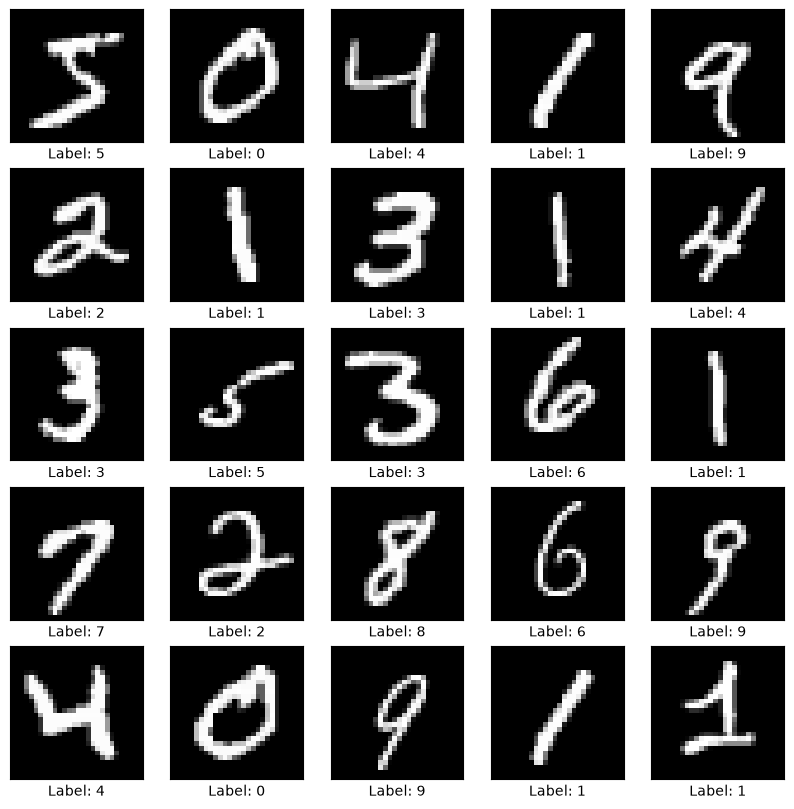

In [ ]:
import tensorflow as tf
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt
import numpy as np

# load dataset MNIST
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()

# menampilkan ukuran datasetnya
print("Jumlah data training:", train_images.shape)
print("Jumlah label training:", train_labels.shape)
print("Jumlah data testing:", test_images.shape)
print("Jumlah label testing:", test_labels.shape)

# normalisasi nilai piksel gambar ke rentang [0,1]
train_images = train_images / 255.0
test_images = test_images / 255.0

# menampilkan contoh gambar
plt.figure(figsize=(10, 10))

for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i], cmap='gray')
    plt.xlabel(f"Label: {train_labels[i]}")

plt.show()

Pada bagian awal, saya mengimpor beberapa library, yaitu TensorFlow untuk membuat model Neural Network, MNIST untuk mengambil dataset, Matplotlib untuk menampilkan gambar dan grafik, serta NumPy untuk pengolahan data numerik.

Selanjutnya, dataset MNIST dimuat menggunakan mnist.load_data(). Dataset ini terdiri dari 60.000 gambar untuk training dan 10.000 gambar untuk testing. Setiap gambar berukuran 28 × 28 piksel dan memiliki label angka 0 sampai 9. Saya kemudian menggunakan .shape untuk memeriksa ukuran dataset dan memastikan jumlah gambar serta label sudah sesuai.

Sebelum digunakan, nilai piksel pada gambar dinormalisasi dengan membaginya dengan 255 sehingga berada pada rentang 0 sampai 1. Setelah itu, saya menampilkan 25 contoh gambar dari data training dalam susunan 5 × 5 menggunakan Matplotlib. Setiap gambar ditampilkan dalam warna grayscale beserta label angka sebenarnya.

Dari visualisasi tersebut, terlihat bahwa dataset MNIST berisi gambar tulisan tangan angka 0–9 dengan bentuk tulisan yang beragam. Dataset inilah yang nantinya digunakan model untuk mempelajari pola dan mengenali angka.

## Pembuatan Model Neural Network

Pada tahap ini, dibuat model Neural Network menggunakan Sequential yang terdiri dari satu input layer, satu hidden layer, dan satu output layer. Model digunakan untuk mengenali dan mengklasifikasikan gambar angka tulisan tangan dari dataset MNIST.

In [ ]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense

# membuat model Neural Network
model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),  # mengubah gambar 28x28 menjadi vektor 1D dengan panjang 784
    Dense(128, activation='relu'),  # hidden layer dengan 128 neuron
    Dense(10, activation='softmax')  # output layer dengan 10 neuron untuk klasifikasi angka 0-9
])

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

Pada bagian ini, saya membuat model Neural Network menggunakan Sequential dengan beberapa layer. Input menentukan ukuran gambar yang digunakan, yaitu 28 × 28 piksel. Kemudian, Flatten() mengubah gambar menjadi deretan 784 nilai agar dapat diproses oleh model. Selanjutnya, terdapat Dense(128) sebagai hidden layer dengan 128 neuron yang menggunakan aktivasi ReLU untuk mempelajari pola gambar. Pada bagian output, digunakan Dense(10) dengan aktivasi Softmax untuk menentukan hasil klasifikasi angka 0 sampai 9. Terakhir, model.summary() digunakan untuk melihat susunan layer dan jumlah parameter pada model.

## Kompilasi dan Pelatihan Model

Pada tahap ini, model dikompilasi dengan menentukan optimizer, loss function, dan metrik evaluasi. Selanjutnya, model dilatih menggunakan data training selama 10 epoch.

In [ ]:
# kompilasi model
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# melatih model dengan data training
history = model.fit(
    train_images,
    train_labels,
    epochs=10,
    validation_split=0.1
)

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9199 - loss: 0.2782 - val_accuracy: 0.9662 - val_loss: 0.1270
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9633 - loss: 0.1252 - val_accuracy: 0.9723 - val_loss: 0.0947
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9751 - loss: 0.0852 - val_accuracy: 0.9752 - val_loss: 0.0873
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9824 - loss: 0.0620 - val_accuracy: 0.9768 - val_loss: 0.0832
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9869 - loss: 0.0465 - val_accuracy: 0.9782 - val_loss: 0.0810
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9907 - loss: 0.0349 - val_accuracy: 0.9773 - val_loss: 0.0847
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9933 - loss: 0.0259 - val_accuracy: 0.9770 - val_loss: 0.0862
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9954 - loss: 0.0196 

Pada bagian ini, saya melakukan kompilasi dan pelatihan model. Optimizer adam digunakan untuk mengoptimalkan proses pembelajaran, sedangkan sparse_categorical_crossentropy digunakan untuk menghitung kesalahan prediksi karena label berupa angka 0–9. Metrik accuracy digunakan untuk mengukur tingkat ketepatan model.

Selanjutnya, model.fit() melatih model menggunakan data training selama 10 epoch. Parameter validation_split=0.1 berarti 10% data training digunakan sebagai data validasi untuk melihat kemampuan model selama proses pelatihan. Hasil pelatihan disimpan dalam variabel history agar dapat dianalisis dan divisualisasikan.

## Evaluasi Model

Pada tahap ini, model dievaluasi menggunakan data testing untuk mengetahui tingkat akurasi dan nilai kesalahan model dalam mengenali gambar angka tulisan tangan yang belum digunakan selama proses pelatihan.

In [ ]:
# mengevaluasi model dengan data pengujian
test_loss, test_acc = model.evaluate(test_images, test_labels)

print(f'\nTest accuracy: {test_acc}')
print(f'Test loss: {test_loss}')

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9706 - loss: 0.1113

Test accuracy: 0.9706000089645386
Test loss: 0.11129278689622879


Pada bagian ini, saya mengevaluasi model menggunakan data testing yang sebelumnya tidak digunakan dalam pelatihan. model.evaluate() menghasilkan nilai test accuracy untuk mengukur ketepatan prediksi dan test loss untuk melihat tingkat kesalahan model. Kedua hasil tersebut kemudian ditampilkan menggunakan print() untuk mengetahui performa model dalam mengenali gambar angka.

## Visualisasi Hasil Pelatihan

Pada tahap ini, hasil pelatihan model divisualisasikan menggunakan grafik untuk melihat perubahan accuracy dan loss pada data training maupun validasi selama 10 epoch.

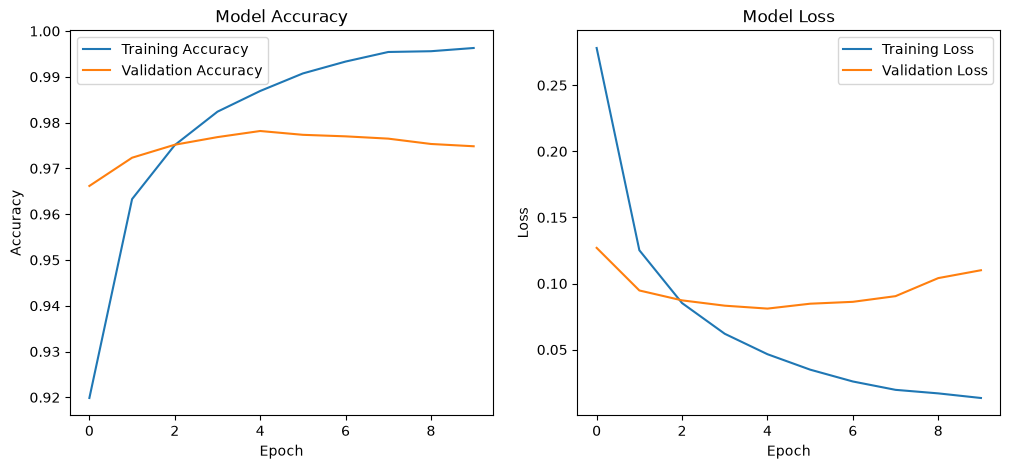

In [ ]:
# fungsi untuk menampilkan grafik hasil training
def plot_history(history):
    plt.figure(figsize=(12, 5))

    # grafik accuracy
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Model Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    # grafik loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Model Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.show()

plot_history(history)

Pada bagian ini, saya membuat fungsi plot_history() untuk menampilkan grafik hasil pelatihan model. Grafik pertama menunjukkan perubahan accuracy pada data training dan validation, sedangkan grafik kedua menunjukkan perubahan loss pada kedua data tersebut. Dengan grafik ini, saya dapat melihat perkembangan proses pembelajaran model dan mengetahui apakah model mengalami overfitting. Fungsi plot_history(history) digunakan untuk menampilkan kedua grafik berdasarkan hasil pelatihan sebelumnya.

## Prediksi Menggunakan Data Testing

Pada tahap ini, model digunakan untuk memprediksi gambar angka tulisan tangan dari data testing. Hasil prediksi kemudian dibandingkan dengan label sebenarnya untuk mengetahui kemampuan model dalam mengenali angka.

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


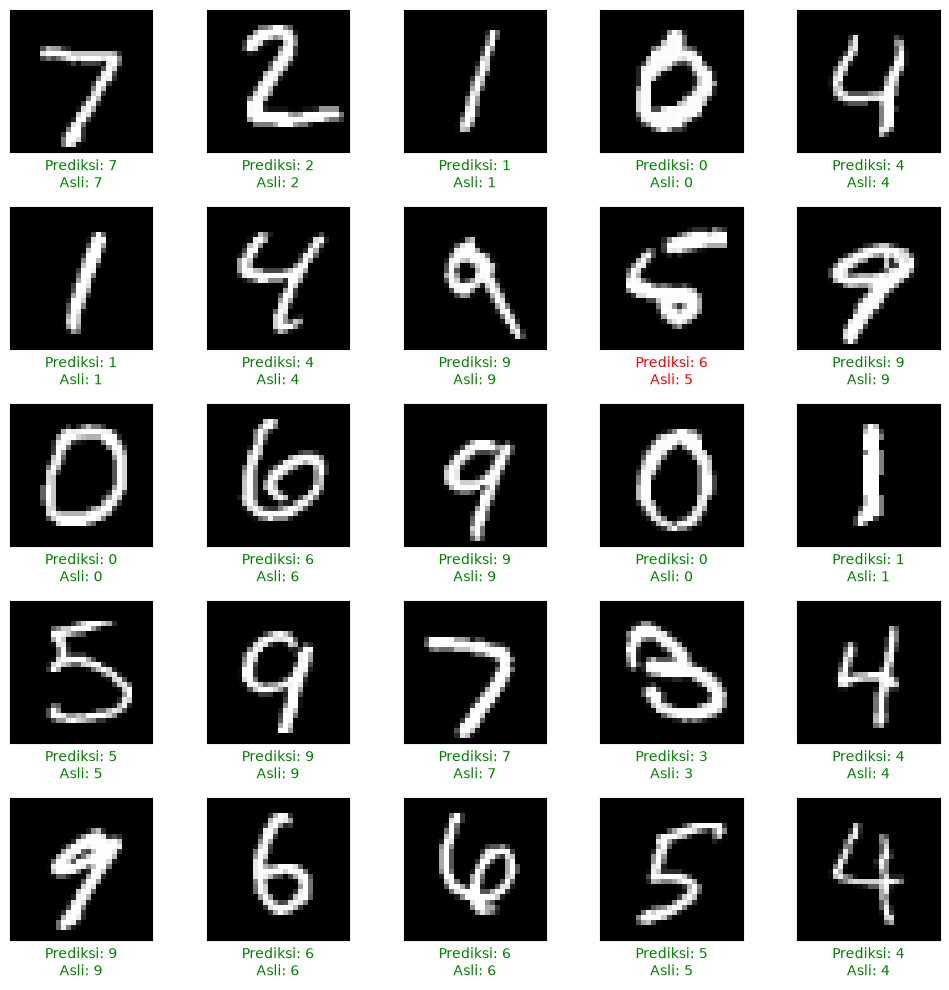

In [ ]:
# melakukan prediksi pada data testing
predictions = model.predict(test_images)

# menampilkan beberapa hasil prediksi
plt.figure(figsize=(10, 10))

for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)

    plt.imshow(test_images[i], cmap='gray')

    predicted_label = np.argmax(predictions[i])
    true_label = test_labels[i]

    color = 'green' if predicted_label == true_label else 'red'

    plt.xlabel(
        f"Prediksi: {predicted_label}\nAsli: {true_label}",
        color=color
    )

plt.tight_layout()
plt.show()

Pada bagian ini, saya melakukan prediksi terhadap seluruh data testing menggunakan model.predict(). Selanjutnya, saya menampilkan 25 gambar pertama beserta hasil prediksi dan label aslinya. np.argmax() digunakan untuk mengambil angka dengan nilai probabilitas tertinggi sebagai hasil prediksi. Warna hijau menunjukkan prediksi benar, sedangkan warna merah menunjukkan prediksi yang salah. Dengan demikian, saya dapat melihat secara langsung kemampuan model dalam mengenali tulisan tangan angka 0–9.

**Kesimpulan**  
Berdasarkan praktikum yang telah dilakukan, saya berhasil membangun dan melatih model Neural Network untuk mengenali gambar angka tulisan tangan menggunakan dataset MNIST. Model dilatih selama 10 epoch dengan 128 neuron pada hidden layer dan menghasilkan akurasi pengujian sebesar 97,06%.

Hasil tersebut menunjukkan bahwa model mampu mengenali sebagian besar gambar angka dengan baik. Melalui grafik accuracy dan loss serta visualisasi hasil prediksi, saya juga dapat mengamati perkembangan pelatihan dan melihat kesalahan prediksi yang masih terjadi. Secara keseluruhan, praktikum ini membantu saya memahami tahapan membangun, melatih, mengevaluasi, dan menggunakan model Neural Network untuk klasifikasi gambar.